In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
SEED = 37

In [15]:
# Load the entire portfolio dataset
data = pd.read_csv("HW5Portfolio25.csv")
dates = pd.to_datetime(data["Date"], format="%Y%m%d") # Convert the dates column to date format instead of ints
X = data.drop(columns="Date").apply(pd.to_numeric, errors="coerce") 

valid_X = X.notna().all(axis=1)
X = X.loc[valid_X]
dates = dates.loc[valid_X]
print("Rows kept:", len(X), "| Portfolios:", X.shape[1], "|", dates.min().date(), "to", dates.max().date())

# Equal-weighted average return, a simple market measurement used later to describe clusters
market = pd.Series(X.mean(axis=1).to_numpy(), index=dates, name="market")

Rows kept: 25438 | Portfolios: 25 | 1926-07-01 to 2023-02-28


## (a) PCA
**Standardization:** all 25 series are daily returns in the same units, so I run PCA on the raw data. Standardizing would give each portfolio equal weight regardless of its volatility and discard the useful information about which portfolios drive the variation. 

**Number of components:** I look at the scree plot (where the curve flattens) and the cumulative variance, and keep the smallest number of PCs reaching 90% of variance.

In [16]:
pca_all = PCA().fit(X)
explained = pca_all.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_components = np.argmax(cumulative >= 0.90) + 1
print(f"Principal components for at least 90% variance: {n_components} (cumulative = {cumulative[n_components]:.4f})")
print(f"Variance explained by the first {n_components} PCs: {np.round(explained[:6], 4)}")

Principal components for at least 90% variance: 6 (cumulative = 0.9200)
Variance explained by the first 6 PCs: [0.6518 0.133  0.0525 0.0301 0.0252 0.0137]


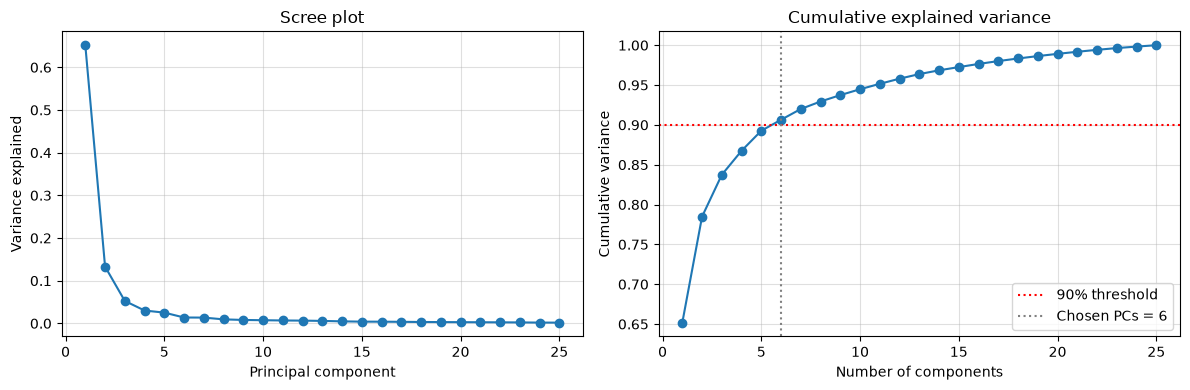

In [17]:
components = np.arange(1, len(explained) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(components, explained, marker="o")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Variance explained")
axes[1].plot(components, cumulative, marker="o")
axes[1].axhline(0.90, color="red", ls=":", label="90% threshold")
axes[1].axvline(n_components, color="gray", ls=":", label=f"Chosen PCs = {n_components}")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative variance")
axes[1].legend()
for a in axes: a.grid(alpha=0.4)
plt.tight_layout(); plt.show()

In [18]:
pca = PCA(n_components=n_components)
scores = pca.fit_transform(X)
pc_cols = [f"PC{i}" for i in range(1, n_components + 1)]
pc_scores = pd.DataFrame(scores, columns=pc_cols, index=dates)
display(pc_scores.head(20))

,PC1,PC2,PC3,PC4,PC5,PC6
Date,,,,,,
1926-07-01,0.147804,-0.500030,0.740417,0.203009,0.323630,0.928243
1926-07-02,0.640377,0.210350,-0.631616,1.456718,1.295260,-1.536060
1926-07-06,0.488396,0.185949,-0.479472,-0.453191,0.154566,-0.713260
1926-07-07,-0.425375,-0.894778,-1.255452,-0.179676,-0.105771,1.555379
1926-07-08,0.503189,0.265711,-0.925185,0.543001,0.998305,-0.914831
1926-07-09,-1.645876,1.902472,0.788244,-1.062659,-1.667565,0.389809
1926-07-10,1.220742,-0.434880,-1.427067,-0.784138,0.433714,-0.144875
1926-07-12,0.589481,0.210954,0.323421,-0.030299,-0.911247,-0.023185
1926-07-13,0.910687,-0.690586,0.699492,0.712619,0.935837,-0.746132


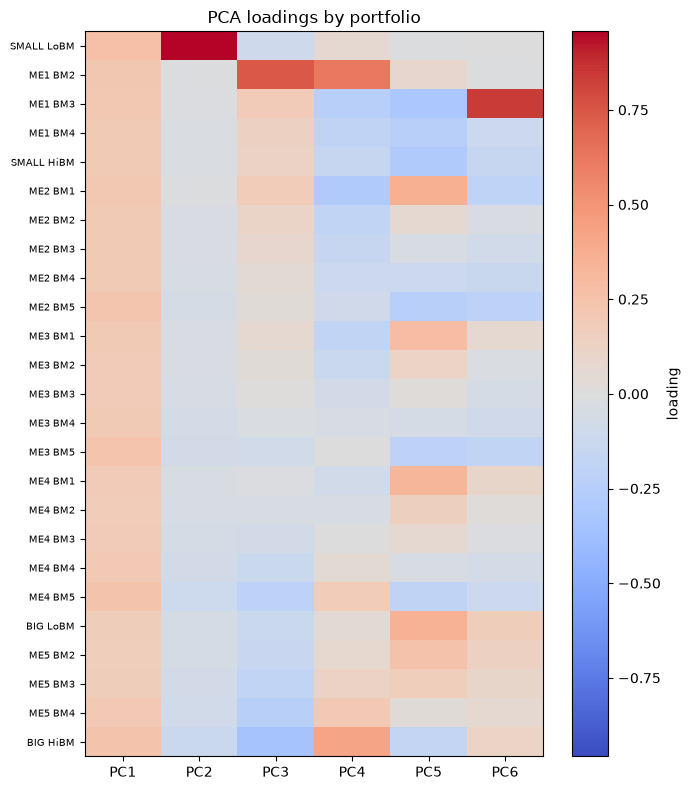

In [19]:
# Loadings: how strongly each portfolio contributes to each PC (helps interpret the PCs)
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=pc_cols)
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(loadings, aspect="auto", cmap="coolwarm", vmin=-loadings.abs().max().max(), vmax=loadings.abs().max().max())
ax.set_xticks(range(n_components)); ax.set_xticklabels(pc_cols)
ax.set_yticks(range(len(loadings))); ax.set_yticklabels(loadings.index, fontsize=7)
ax.set_title("PCA loadings by portfolio"); fig.colorbar(im, label="loading"); plt.tight_layout(); plt.show()

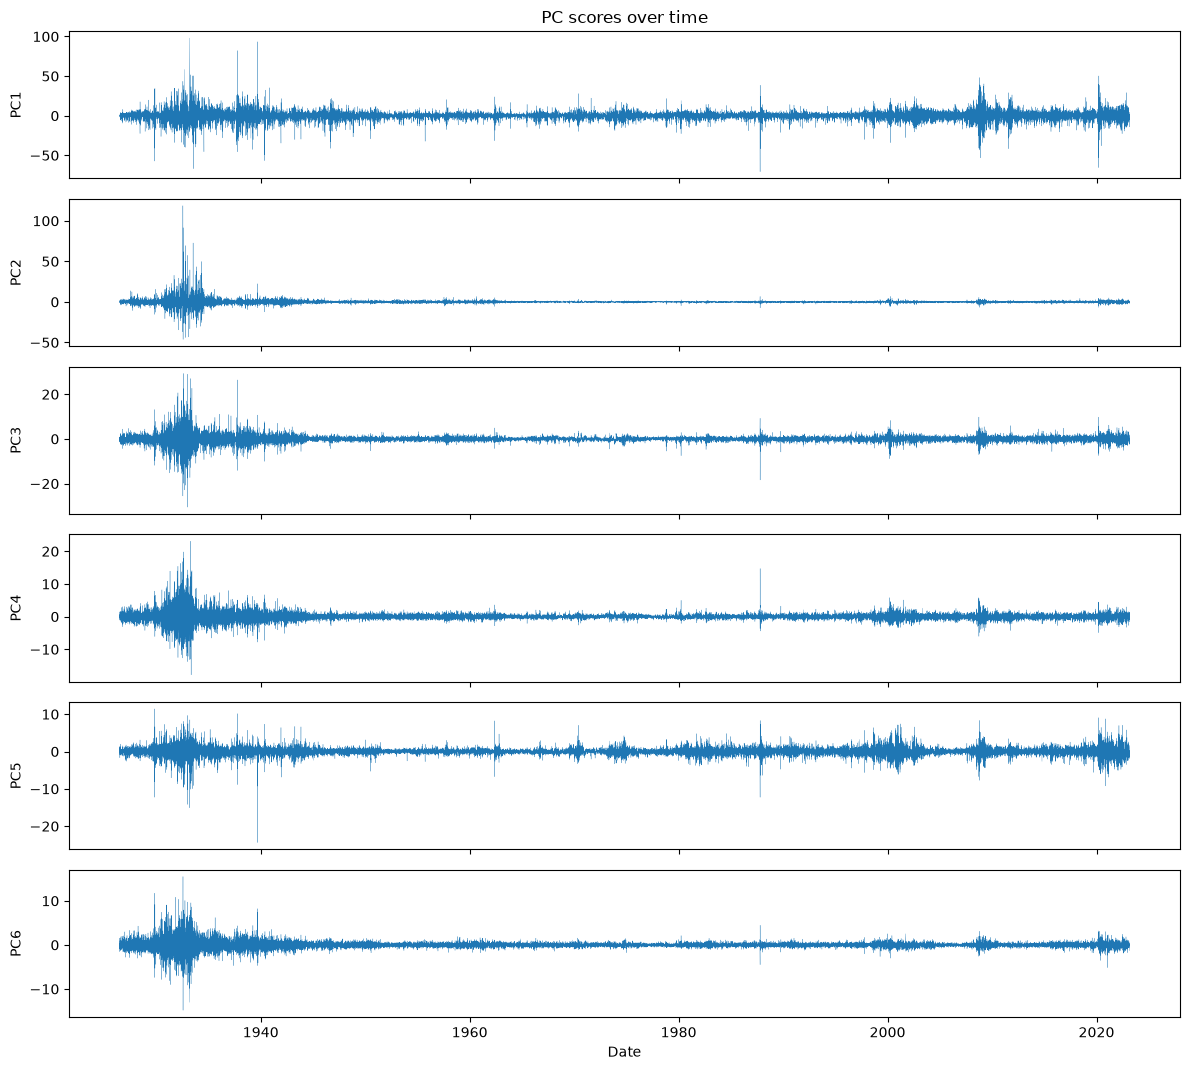

In [20]:
fig, axes = plt.subplots(n_components, 1, figsize=(12, 1.8 * n_components), sharex=True)
axes = np.atleast_1d(axes)
for ax, pc in zip(axes, pc_cols):
    ax.plot(pc_scores.index, pc_scores[pc], lw=0.2)
    ax.set_ylabel(pc)
axes[0].set_title("PC scores over time")
axes[-1].set_xlabel("Date")
plt.tight_layout(); plt.show()

## Helper methods shared by (b), (c), and (d)

In [25]:
PALETTE = plt.get_cmap("tab10").colors 

def relabel_by_vol(labels):
    vol = pd.Series(market.to_numpy()).groupby(labels).std().sort_values()
    mapping = {old: new for new, old in enumerate(vol.index)}
    return np.array([mapping[l] for l in labels])

def profile(labels):
    df = pd.DataFrame({"cluster": labels, "market": market.to_numpy()})
    g = df.groupby("cluster")["market"]
    return pd.DataFrame({"days": g.size(), "share": g.size() / len(df),
                         "mean_return": g.mean(), "return_std": g.std()}).round(4)

def scatter_pairs(labels, centers=None, title=""):
    pairs = [(0, 1), (0, 2), (1, 2)] if n_components >= 3 else [(0, 1)]
    fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 5))
    axes = np.atleast_1d(axes)
    for ax, (i, j) in zip(axes, pairs):
        for c in np.unique(labels):
            m = labels == c
            ax.scatter(pc_scores.iloc[m, i], pc_scores.iloc[m, j], s=5, alpha=.4, color=PALETTE[c], label=f"Cluster {c}")
        if centers is not None:
            ax.scatter(centers[:, i], centers[:, j], marker="X", s=160, color="black", edgecolor="white", label="Centroids")
        ax.set(xlabel=pc_cols[i], ylabel=pc_cols[j]); ax.grid(alpha=.3)
    axes[0].legend(markerscale=2, fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()

def monthly_share(labels, k):
    df = pd.DataFrame({"cluster": labels}, index=dates.to_numpy())
    s = pd.crosstab(df.index.to_period("M"), df["cluster"], normalize="index")
    return s.reindex(columns=range(k), fill_value=0)

def plot_monthly_share(share, title):
    s = share.copy(); s.index = s.index.to_timestamp()
    ax = s.plot.area(figsize=(13, 4), color=[PALETTE[c] for c in s.columns], linewidth=0)
    ax.set(title=title, xlabel="Date", ylabel="Share of trading days", ylim=(0, 1))
    ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

### (b) Hierarchical Clustering Analysis on PCA Results
**Settings:**
- Features: The 6 principal component scores chosen above, noise in the low variance PCs is discarded.
- Distance: Euclidean (natural for PC scores)
- Linkage: I compare ward, complete, and average linkage using cophenetic correlation (how faithfully the tree distances reflect the original pairwise distances). This is done on a random sample because the full data has too many days for a dendrogram or pairwise distance matrix.
- Number of clusters: chosen by considering the silhouette score on the same sample. 

Cophenetic correlation by linkage: {'ward': np.float64(0.556), 'complete': np.float64(0.647), 'average': np.float64(0.892)}


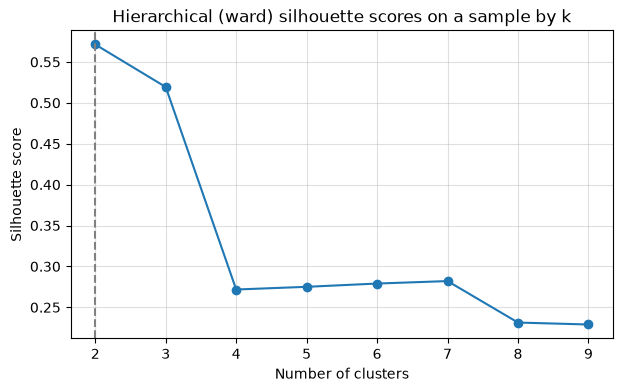

Highest silhouette score in this range: k=2


In [22]:
# Reproducible sample for comparing clusters and drawing the dendrogram
sample = pc_scores.sample(n=min(5000, len(pc_scores)), random_state=SEED)
orig_dist = pdist(sample.to_numpy())

coph = {}
for method in ["ward", "complete", "average"]:
    coph[method] = cophenet(linkage(sample.to_numpy(), method=method), orig_dist)[0]
print("Cophenetic correlation by linkage:", {k: round(v, 3) for k, v in coph.items()})

k_vals = range(2, 10) # Compare silhouette scores for different cluster counts
sil_h = [silhouette_score(sample, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(sample)) for k in k_vals]
best_k_h = k_vals[int(np.argmax(sil_h))]

plt.figure(figsize=(7, 4))
plt.plot(list(k_vals), sil_h, marker="o")
plt.axvline(best_k_h, color="gray", ls="--")
plt.xlabel("Number of clusters"); plt.ylabel("Silhouette score")
plt.title("Hierarchical (ward) silhouette scores on a sample by k")
plt.grid(alpha=0.4); plt.show()

print(f"Highest silhouette score in this range: k={best_k_h}")

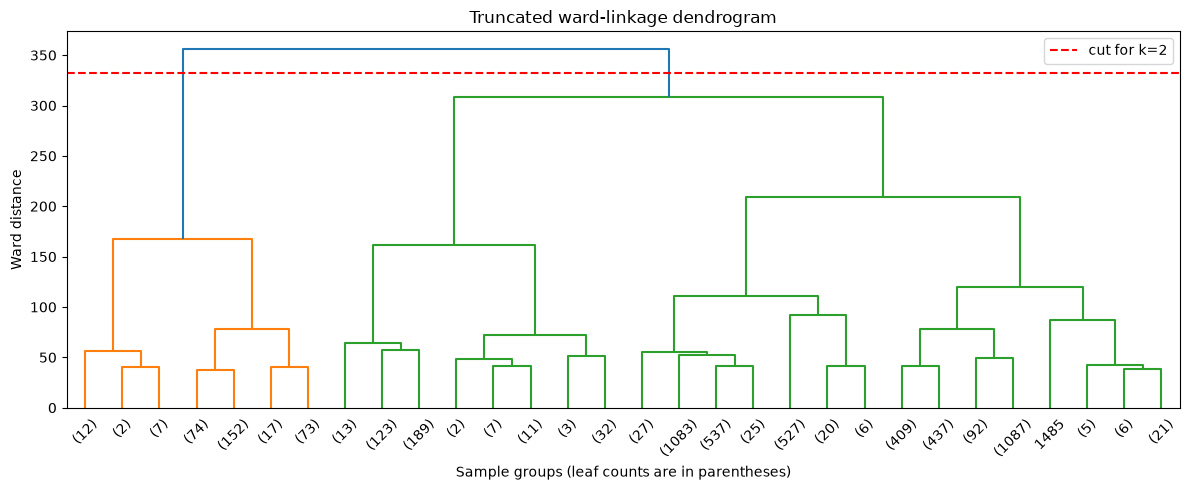

In [23]:
Z = linkage(sample.to_numpy(), method="ward", metric="euclidean")
cut = (Z[-(best_k_h - 1), 2] + Z[-best_k_h, 2]) / 2
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=cut)
plt.axhline(cut, color="red", ls="--", label=f"cut for k={best_k_h}")
plt.xlabel("Sample groups (leaf counts are in parentheses)")
plt.ylabel("Ward distance")
plt.title("Truncated ward-linkage dendrogram"); plt.legend()
plt.tight_layout(); plt.show()

,days,share,mean_return,return_std
cluster,,,,
0,23188,0.9115,0.2678,0.8938
1,2250,0.0885,-2.1915,1.3165


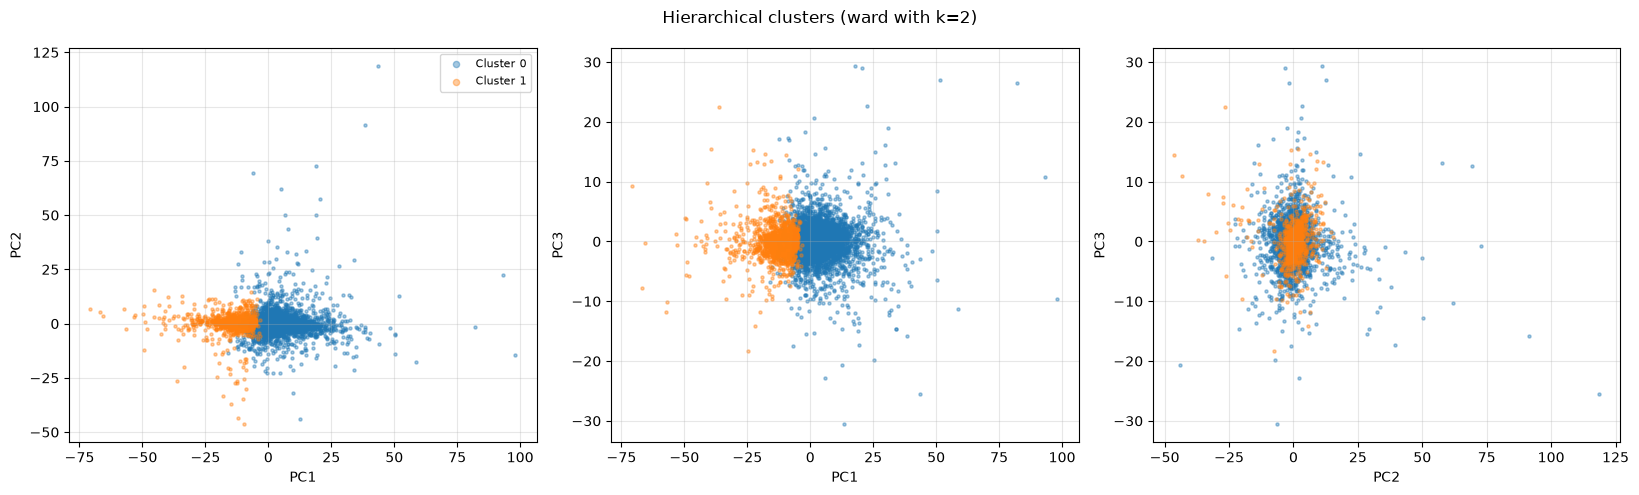

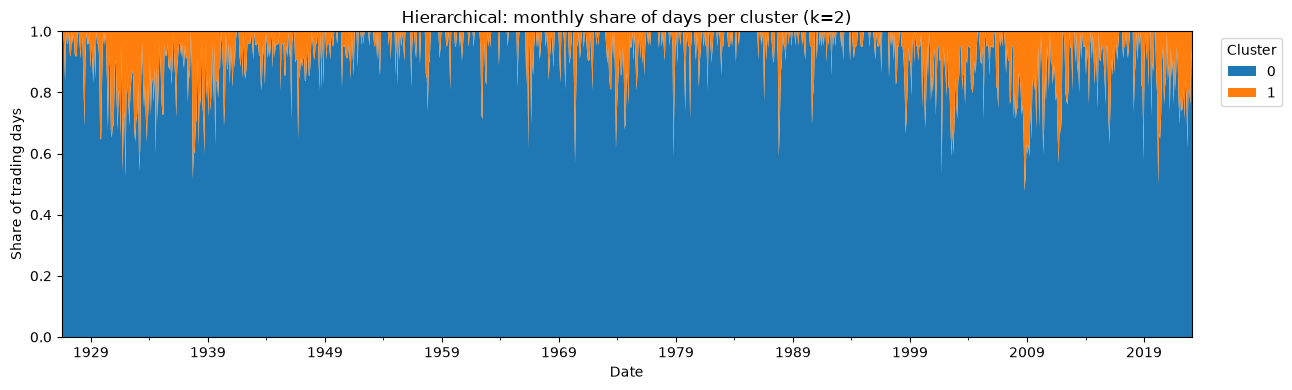

In [26]:
hier_labels = relabel_by_vol(AgglomerativeClustering(n_clusters=best_k_h, linkage="ward").fit_predict(pc_scores))

display(profile(hier_labels))
scatter_pairs(hier_labels, title=f"Hierarchical clusters (ward with k={best_k_h})")
plot_monthly_share(monthly_share(hier_labels, best_k_h), f"Hierarchical: monthly share of days per cluster (k={best_k_h})")

### (c) K-Means Clustering on the PC Scores
**Settings:**
- **Features:** Same 6 PC scores. K-Means minimizes the within-cluster squred Euclidean distance, which fits the PC scores.
- **Initialization:** `n_init=20` random restarts and keep the best, K-Means can land in poor local optima.
- **k:** elbow plot and silhouette score on the sample help to decide k. The elbow is a sanity check while the silhouette score picks the k value.

In [ ]:
inertias, sil_k = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(sample)
    inertias.append(km.inertia_)
    if k >= 2:
        sil_k.append(silhouette_score(sample, km.labels_))
k_range = list(range(2, 11))
best_k_km = k_range[int(np.argmax(sil_k))]

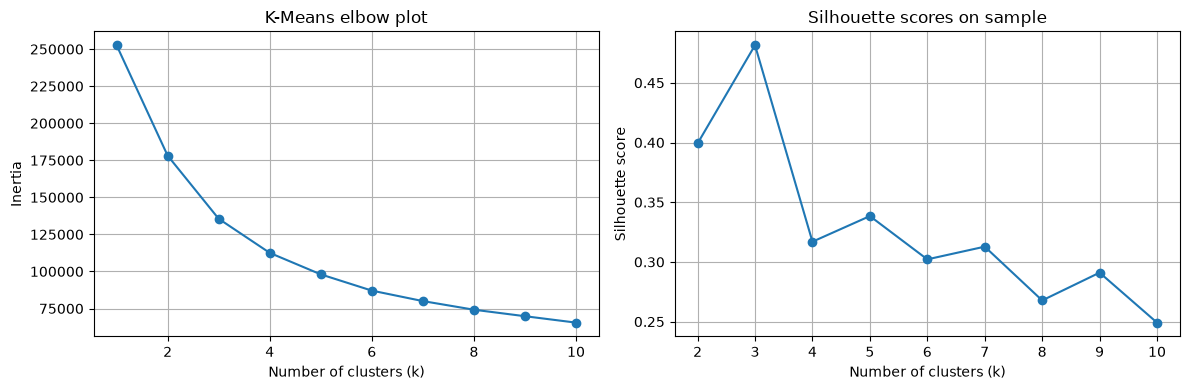

Highest silhouette score in this range: k=3


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 11), inertias, marker="o")
axes[0].set(title="Elbow plot", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[0].grid(alpha=0.4)

axes[1].plot(k_range, sil_k, marker="o")
axes[1].set(title="Silhouette scores on sample", xlabel="Number of clusters (k)", ylabel="Silhouette score")
axes[1].grid(alpha=0.4)
plt.tight_layout(); plt.show()

print(f"Highest silhouette score in this range: k={best_k_km}")

In [ ]:
kmeans = KMeans(n_clusters=best_k_km, n_init=20, random_state=SEED).fit(pc_scores)

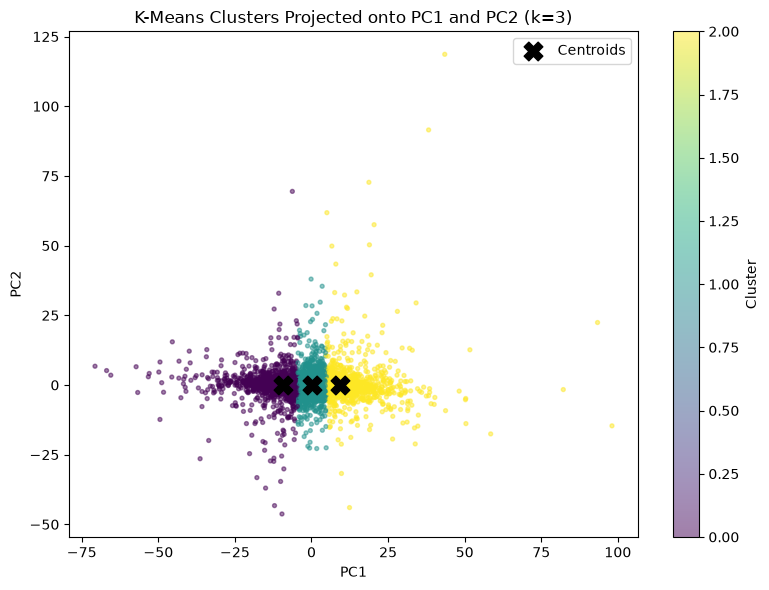

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(clustered_kmeans["PC1"], clustered_kmeans["PC2"], c=clustered_kmeans["cluster"], cmap="viridis", s=8, alpha=0.5)
centers = kmeans.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=180, color="black", label="Centroids")
ax.set(xlabel="PC1", ylabel="PC2", title=f"K-Means Clusters Projected onto PC1 and PC2 (k={chosen_k})")
fig.colorbar(points, ax=ax, label="Cluster")
ax.legend()
plt.tight_layout(); plt.show()

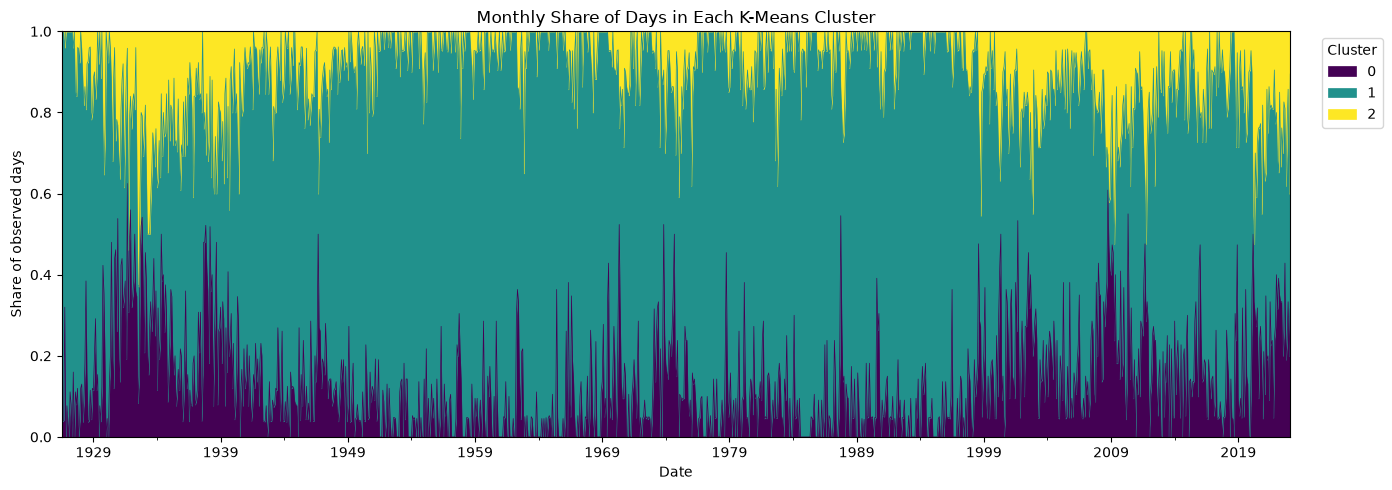

In [17]:
monthly_share = pd.crosstab(clustered_kmeans.index.to_period("M"), clustered_kmeans["cluster"], normalize="index").reindex(columns=range(chosen_k), fill_value=0)

monthly_share.index = monthly_share.index.to_timestamp()
ax = monthly_share.plot.area(figsize=(14, 5), colormap="viridis", linewidth=0.5)
ax.set(xlabel="Date", ylabel="Share of observed days", title="Monthly Share of Days in Each K-Means Cluster", ylim=(0, 1))
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

State changes: 32
row_0
1926-07    0
1926-11    1
1927-12    0
1929-09    1
1933-04    0
1937-06    1
1938-07    0
1945-03    1
1945-11    0
1948-12    1
1949-11    0
1953-08    1
1954-06    0
1957-09    1
1958-05    0
1960-05    1
1961-03    0
1970-01    1
1970-12    0
1973-12    1
1975-04    0
1980-02    1
1980-08    0
1981-08    1
1982-12    0
1990-08    1
1991-04    0
2001-04    1
2001-12    0
2008-01    1
2009-07    0
2020-03    1
2020-05    0
Freq: M, Name: USREC, dtype: int64
[('1926-11', '1927-12'), ('1929-09', '1933-04'), ('1937-06', '1938-07'), ('1945-03', '1945-11'), ('1948-12', '1949-11'), ('1953-08', '1954-06'), ('1957-09', '1958-05'), ('1960-05', '1961-03'), ('1970-01', '1970-12'), ('1973-12', '1975-04'), ('1980-02', '1980-08'), ('1981-08', '1982-12'), ('1990-08', '1991-04'), ('2001-04', '2001-12'), ('2008-01', '2009-07'), ('2020-03', '2020-05')]


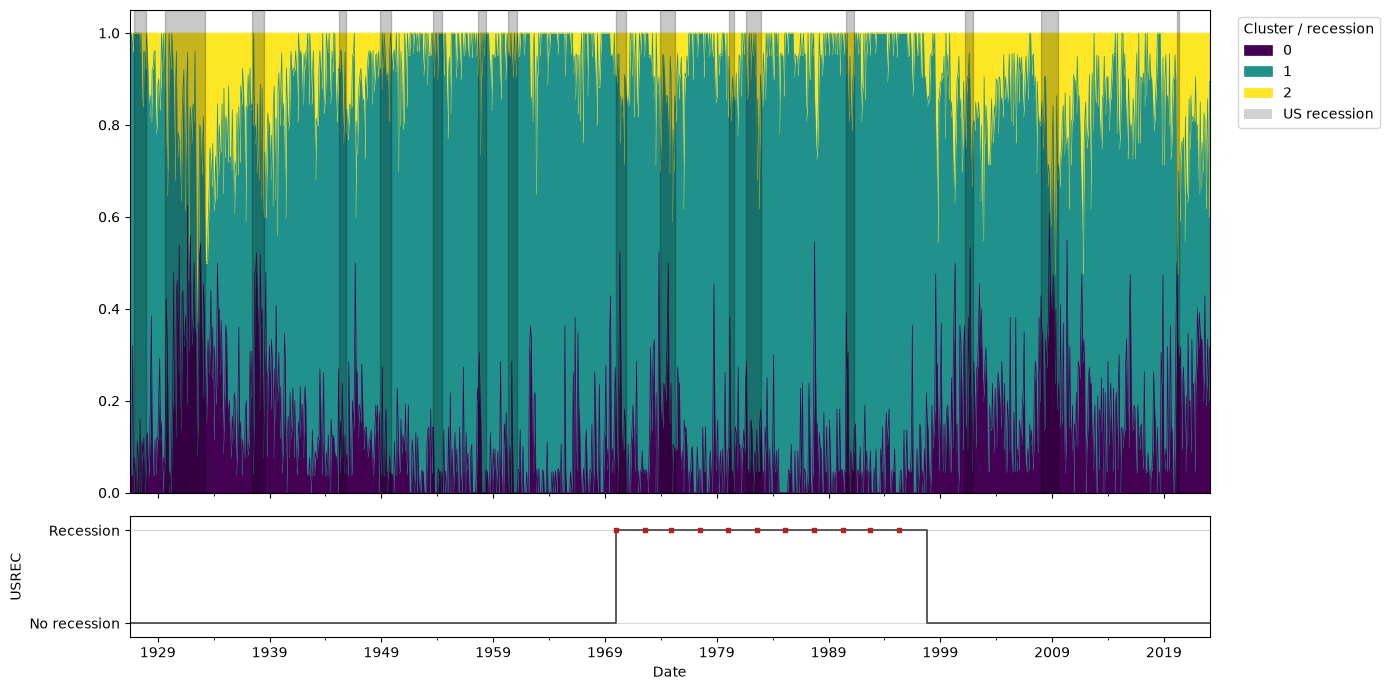

In [22]:
cluster_months = monthly_share.copy()
cluster_months.index = cluster_months.index.to_period("M")

usrec = pd.read_csv("HW5USREC.csv", parse_dates=["observation_date"])
usrec["month"] = usrec["observation_date"].dt.to_period("M")
rec_by_month = usrec.set_index("month")["USREC"].reindex(cluster_months.index).sort_index().astype(int)
changes = rec_by_month.ne(rec_by_month.shift())
print("State changes:", int(changes.iloc[1:].sum()))
cluster_months.index = cluster_months.index.to_timestamp()

recession = rec_by_month.eq(1)
starts = recession & ~recession.shift(1, fill_value=False)
ends = recession & ~recession.shift(-1, fill_value=False)


dates = rec_by_month.index.to_timestamp()

# Keep only the months present in both datasets
if rec_by_month.isna().any():
    raise ValueError("USREC is missing one or more portfolio months.")

# Plot cluster composition above recession periods
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [4, 1]})

cluster_months.plot.area(ax=ax1, colormap="viridis", linewidth=0.5)
for start, end in zip(rec_by_month.index[starts], rec_by_month.index[ends]):
    ax1.axvspan(
        start.to_timestamp(),
        (end + 1).to_timestamp(),
        color="black",
        alpha=0.22,
        zorder=10
    )
month_starts = rec_by_month.index.to_timestamp()
rec_vals = rec_by_month.to_numpy(dtype=int)
month_edges = month_starts.append(
    pd.DatetimeIndex([(rec_by_month.index[-1] + 1).to_timestamp()])
)
step_values = np.append(rec_vals, rec_vals[-1])
ax2.step(month_edges, step_values, where="post", color="0.25", linewidth=1.2)
ax2.scatter(
    month_starts[rec_vals == 1],
    np.ones((rec_vals == 1).sum()),
    color="firebrick",
    s=8,
    marker="s",
    zorder=3,
)

ax2.set_ylim(-0.15, 1.15)
ax2.set_yticks([0, 1], labels=["No recession", "Recession"])
ax2.set_ylabel("USREC")
ax2.set_xlabel("Date")
ax2.grid(axis="y", alpha=0.5)
# Add a legend key for the shaded regions alongside the cluster keys.
handles, labels = ax1.get_legend_handles_labels()
handles.append(Patch(facecolor="black", alpha=0.18))
labels.append("US recession")
ax1.legend(handles, labels, title="Cluster / recession",
           bbox_to_anchor=(1.02, 1), loc="upper left")
print(rec_by_month[rec_by_month.ne(rec_by_month.shift())])
print(list(zip(
    rec_by_month.index[starts].astype(str),
    (rec_by_month.index[ends] + 1).astype(str)
)))
plt.tight_layout(); plt.show()